# ROAD TRAFFIC CRASH PREDICTION

## Project Overview 

Road traffic accidents are a major public safety concern, resulting in loss of lives, injuries, property damage, and economic losses.
Understanding factors associated with road crashes can help authorities identify patterns and develop more effective road safety interventions.
This project aims to develop a machine learning model that predicts road crash severity using historical crash-related data.

## Business Understanding

Road crashes remain a major public safety concern, resulting in fatalities, injuries, and property damage. Understanding the factors associated with crash severity is essential in developing effective road safety strategies. This project seeks to address the challenge by analysing historical road crash records and developing a machine learning model capable of classifying crashes according to their severity. The resulting insights could help identify high-risk conditions and support authorities in making informed decisions towards improving road safety.

## Data Understanding

The dataset was sourced from [World Bank Microdata Library](https://microdata.worldbank.org/index.php/catalog/6249)


**Description of Data:**

The dataset contains 25,252 records and 17 features describing different characteristics of road crashes. The target variable is `severity_index`, which will be used to train the machine learning model.

**Feature Description:**

| Feature | Description |
|---|---|
| `n_crash_reports` | Represents the number of crash reports associated with a record. |
| `contains_fatality_words` | Indicates whether the crash report contains words associated with fatalities (1 = Yes, 0 = No). |
| `contains_pedestrian_words` | Indicates whether the crash report contains pedestrian-related words (1 = Yes, 0 = No). |
| `year` | The year in which the crash occurred. |
| `day_of_week` | The name of the day on which the crash occurred, such as Monday or Tuesday. |
| `hour` | The hour of the day when the crash occurred. |
| `day` | The day of the month when the crash occurred. |
| `weekday` | A numerical representation of the day of the week. |
| `month` | The month in which the crash occurred, represented numerically. |
| `is_weekend` | Indicates whether the crash occurred during a weekend (1 = Yes, 0 = No). |
| `day_part` | Classifies the time of occurrence into different periods of the day, such as morning, afternoon, evening, and night. |
| `distance_to_nairobi` | Represents the geographical distance of the crash location from Nairobi. |
| `contains_vehicle_words` | Indicates whether the crash report contains vehicle-related words (1 = Yes, 0 = No). |
| `severity_index` | The target variable representing the severity category assigned to each crash record. |
| `local_crash_density` | Represents the concentration or frequency of crashes within a particular locality. |
| `season` | Classifies the period of occurrence according to seasonal categories, such as dry, rainy, or transitional. |
| `fatality_mention_ratio` | Represents the proportion of fatality-related mentions associated with a crash record. |

The dataset contains both numerical and categorical variables, making it suitable for classification analysis. The `severity_index` feature will serve as the dependent variable, while the remaining features will initially be considered independent variables, subject to further investigation and feature selection.

## 1. Import Libraries

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load and Inspect the Data

In [2]:
# Display number of rows and columns.

df = pd.read_csv('processed_crash_data.csv')
print(df.shape)

(25252, 17)


In [3]:
# Display the first 10 rows.

df.head(10)

,n_crash_reports,contains_fatality_words,contains_pedestrian_words,year,day_of_week,hour,day,weekday,month,is_weekend,day_part,distance_to_nairobi,contains_vehicle_words,severity_index,local_crash_density,season,fatality_mention_ratio
0,1,0,0,2018.0,Wednesday,20.0,6.0,2.0,6.0,0,evening,7.165499,0,0,3303,dry,0.054249
1,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,56.743166,0,1,1,transitional,0.062719
2,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,27.398293,0,0,481,transitional,0.062719
3,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,60.469275,0,0,5,transitional,0.062719
4,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,4.287275,0,1,7019,transitional,0.062719
5,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,8.644064,0,0,1767,transitional,0.062719
6,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,14.147602,0,1,978,transitional,0.062719
7,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,9.221275,0,0,729,transitional,0.062719
8,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,2.922511,0,0,7267,transitional,0.062719
9,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,night,10.174603,0,0,1987,transitional,0.062719


In [4]:
# Display column names, data types, non-null counts, and the dataset dimensions.

df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 25252 entries, 0 to 25251
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   n_crash_reports            25252 non-null  int64  
 1   contains_fatality_words    25252 non-null  int64  
 2   contains_pedestrian_words  25252 non-null  int64  
 3   year                       10259 non-null  float64
 4   day_of_week                10259 non-null  str    
 5   hour                       10259 non-null  float64
 6   day                        10259 non-null  float64
 7   weekday                    10259 non-null  float64
 8   month                      10259 non-null  float64
 9   is_weekend                 25252 non-null  int64  
 10  day_part                   25252 non-null  str    
 11  distance_to_nairobi        25252 non-null  float64
 12  contains_vehicle_words     25252 non-null  int64  
 13  severity_index             25252 non-null  int64  
 14  l

(25252, 17)

## 3. Clean the Data

Checking for missing values, remove duplicate rows, and drop columns that never change.

In [ ]:
# Count missing values in each column.

missing_values = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': (df.isnull().mean() * 100).round(2)
})

missing_values[missing_values['Missing Values'] > 0]

,Missing Values,Percentage
year,14993,59.37
day_of_week,14993,59.37
hour,14993,59.37
day,14993,59.37
weekday,14993,59.37
month,14993,59.37


In [6]:
# Identify duplicate rows, remove them, and check the dataset size afterwards.

print("Duplicate records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicate records: 9374
Shape after removing duplicates: (15878, 17)


In [7]:
# Find columns with only one unique value and remove them, except for the target column.

constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
    and col != "severity_index"
]

df.drop(columns=constant_columns, inplace=True)

print("Removed columns:", constant_columns)

Removed columns: ['n_crash_reports', 'contains_pedestrian_words', 'contains_vehicle_words']


Many rows have no date or time information. We add a flag column so the model knows which rows are missing it.

In [8]:
# Create an indicator showing whether any of the selected date or time fields are missing in each row.

temporal_columns = [
    "year", "day_of_week", "hour",
    "day", "weekday", "month"
]

df["temporal_info_missing"] = (
    df[temporal_columns].isna().any(axis=1)
).astype(int)

## 4. Exploratory Data Analysis (EDA)



In [9]:
# Calculate the percentage of records in each crash severity class.

severity_percentage = (
    df["severity_index"].value_counts(normalize=True) * 100
)

severity_percentage

severity_index
0    91.718101
1     8.281899
Name: proportion, dtype: float64

The class is imbalanced

**Crashes by day, time of day and season**

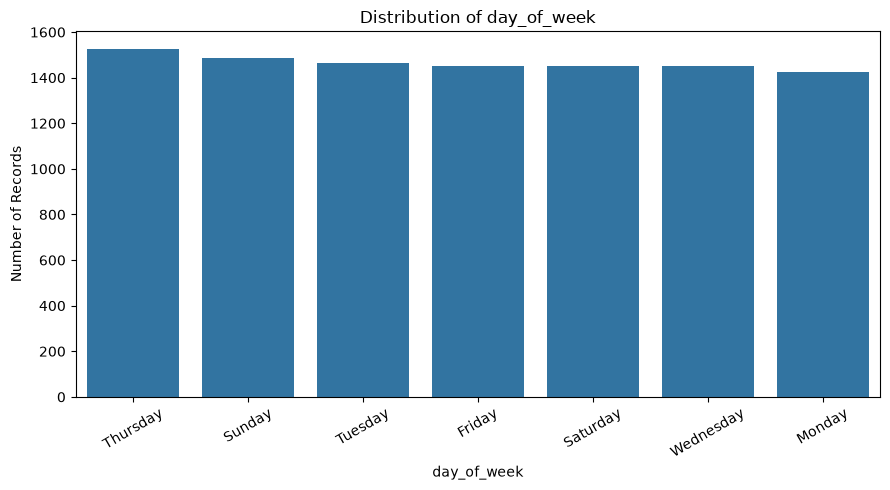

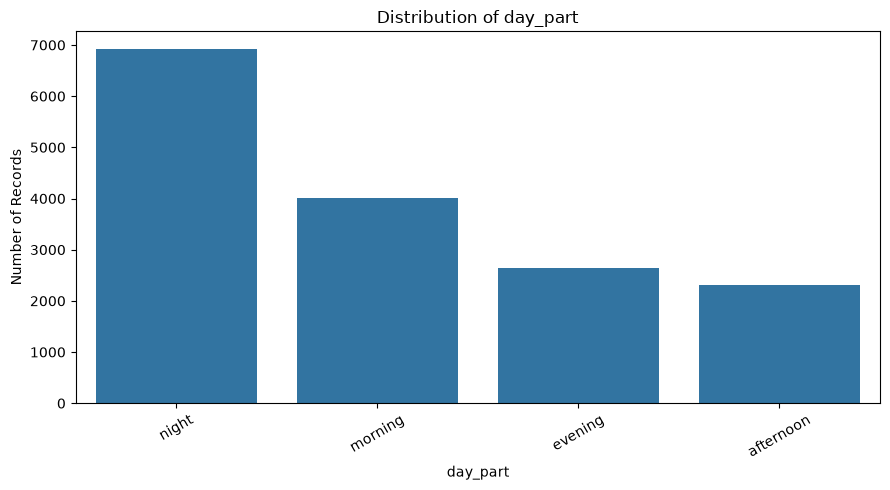

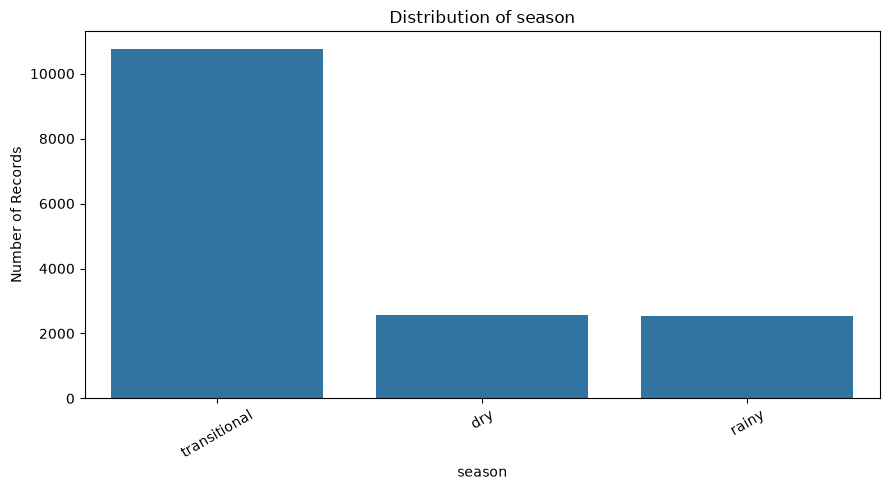

In [10]:
# Draw a count plot for each selected category to compare how often its values occur.

categorical_columns = [
    "day_of_week",
    "day_part",
    "season"
]

for column in categorical_columns:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Records")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

**Crashes by hour**

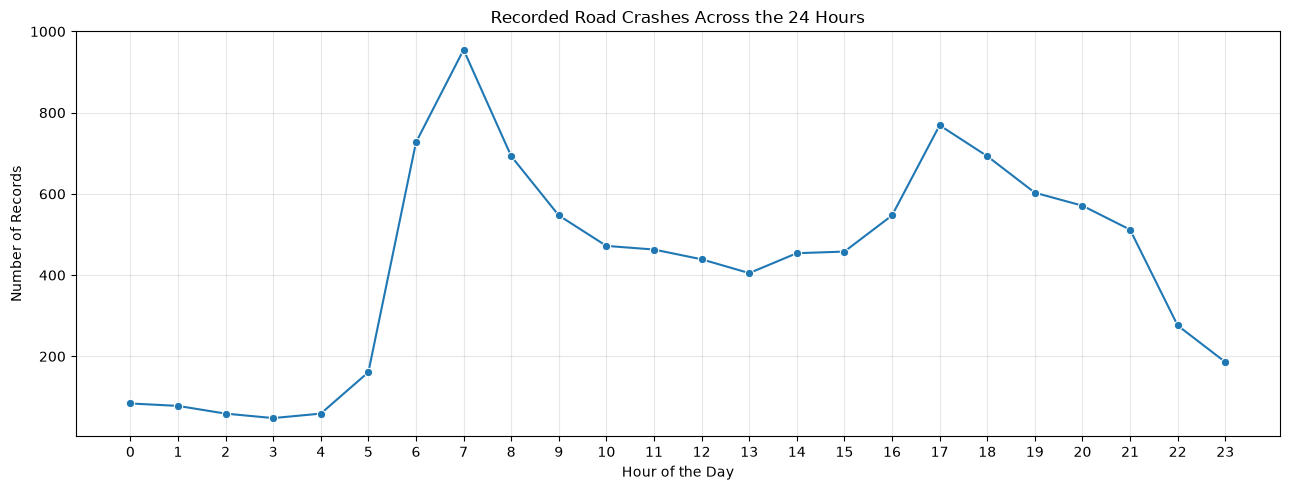

Busiest observed hour: 7 - 955 records
Records with an observed hour: 10259


In [11]:
# Count observed crash times by hour (0 to 23).

hour_values = pd.to_numeric(df["hour"], errors="coerce")
hour_counts = (
    hour_values.dropna().astype(int)
    .value_counts()
    .reindex(range(24), fill_value=0)
)

plt.figure(figsize=(13, 5))
sns.lineplot(x=hour_counts.index, y=hour_counts.values, marker="o")
plt.title("Recorded Road Crashes Across the 24 Hours")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Records")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Busiest observed hour:", int(hour_counts.idxmax()),
      "-", int(hour_counts.max()), "records")
print("Records with an observed hour:", int(hour_counts.sum()))

**Crashes by month**

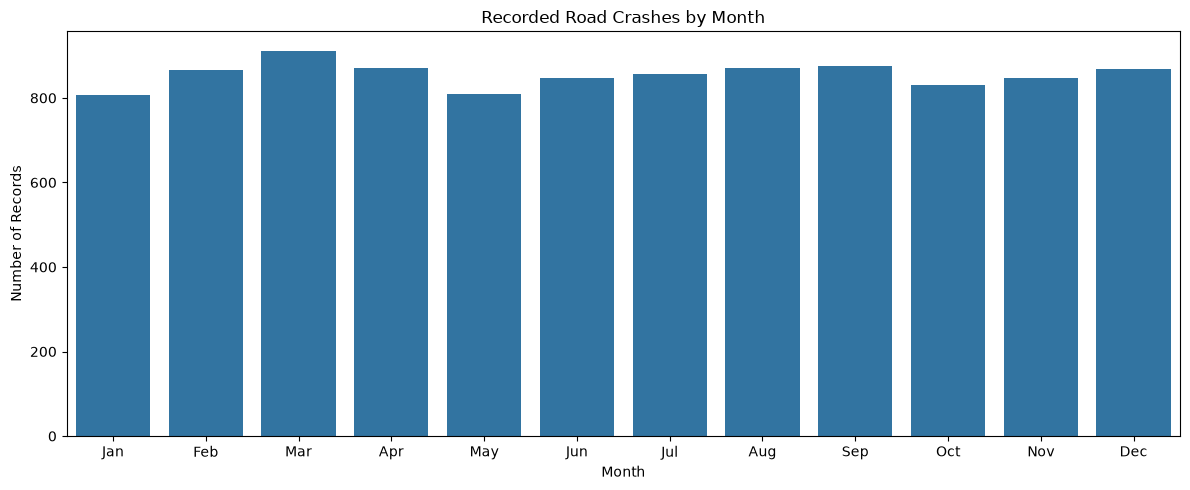

Highest recorded month: Mar - 912 records
Records with an observed month: 10259


In [12]:
# Count observed crashes by month in calendar order.

month_values = pd.to_numeric(df["month"], errors="coerce")
month_counts = (
    month_values.dropna().astype(int)
    .value_counts()
    .reindex(range(1, 13), fill_value=0)
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 5))
sns.barplot(x=month_names, y=month_counts.values)
plt.title("Recorded Road Crashes by Month")
plt.xlabel("Month")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

print("Highest recorded month:", month_names[int(month_counts.values.argmax())],
      "-", int(month_counts.max()), "records")
print("Records with an observed month:", int(month_counts.sum()))

**Correlation between numerical columns**

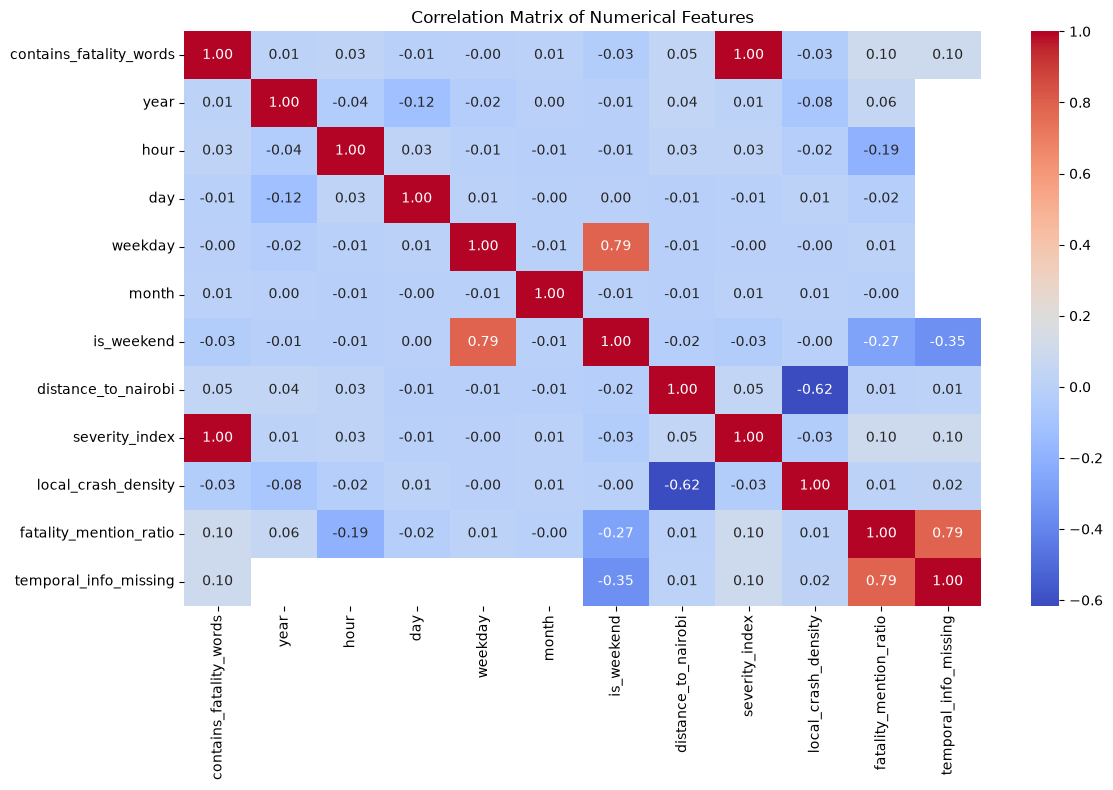

In [13]:
# Calculate and visualize correlations between numerical columns.

correlation_matrix = df.select_dtypes(
    include=["int64", "float64"]
).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

## 5. Feature Selection and Preprocessing

Remove columns that could leak the answer (they are too closely tied to the target) and columns that repeat other information.

In [14]:
# Make a modelling copy, then remove columns identified as leakage or redundant features.

# Make a copy of the cleaned dataset
model_df = df.copy()

# Remove features that could cause data leakage
leakage_columns = [
    "contains_fatality_words",
    "fatality_mention_ratio"
]

# Remove redundant or questionable features
redundant_columns = [
    "day_of_week",
    "is_weekend",
    "day"
]

model_df.drop(
    columns=leakage_columns + redundant_columns,
    inplace=True,
    errors="ignore"
)

print("Dataset shape:", model_df.shape)
print("\nRemaining features:")
print(model_df.columns.tolist())

print("\nMissing values:")
print(model_df.isnull().sum())


Dataset shape: (15878, 10)

Remaining features:
['year', 'hour', 'weekday', 'month', 'day_part', 'distance_to_nairobi', 'severity_index', 'local_crash_density', 'season', 'temporal_info_missing']

Missing values:
year                     5619
hour                     5619
weekday                  5619
month                    5619
day_part                    0
distance_to_nairobi         0
severity_index              0
local_crash_density         0
season                      0
temporal_info_missing       0
dtype: int64


Split the data into inputs `X` and the target `y`.

In [15]:
# Separate the input features (X) from the target variable (y), which is crash severity.

# Define the target variable
X = model_df.drop(columns=["severity_index"])

# Define the target
y = model_df["severity_index"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


Features shape: (15878, 9)
Target shape: (15878,)

Target distribution:
severity_index
0    14563
1     1315
Name: count, dtype: int64


In [16]:
# Import preprocessing tools and identify which input columns are numerical or categorical.

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)


Numerical features: ['year', 'hour', 'weekday', 'month', 'distance_to_nairobi', 'local_crash_density', 'temporal_info_missing']

Categorical features: ['day_part', 'season']


Keep 80% of the data for training and 20% for testing.

In [17]:
# Split the data into training and testing sets while preserving the class proportions.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))


Training set: (12702, 9)
Testing set: (3176, 9)

Training target distribution:
severity_index
0    0.917178
1    0.082822
Name: proportion, dtype: float64

Testing target distribution:
severity_index
0    0.917191
1    0.082809
Name: proportion, dtype: float64


Fill in missing values, scale the numbers, and convert categories to numbers.

In [18]:
# Set up preprocessing: fill missing numerical values and scale them; fill and encode categories.

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


## 6. Train the Models

Train three models: Logistic Regression, Decision Tree and Random Forest.

In [19]:
# Define three classification algorithms, then train each one using the same preprocessing steps.

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Define the models
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        max_depth=15,
        min_samples_split=10,
        random_state=42,
        n_jobs=-1
    )
}

# Store trained pipelines
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully.")


Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


## 7. Evaluate the Models

Because Class 1 is rare, accuracy alone can be misleading, so we also check precision, recall and F1.

In [20]:
# Predict the test-set classes and calculate evaluation metrics for each trained model.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

results = []

for name, pipeline in trained_models.items():

    # Generate predictions
    y_pred = pipeline.predict(X_test)

    # Get probabilities for class 1
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

results_df


,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Logistic Regression,0.576826,0.113653,0.604563,0.191336,0.120578
2,Random Forest,0.716625,0.121284,0.387833,0.184783,0.108667
1,Decision Tree,0.550378,0.099105,0.547529,0.167832,0.095237


**Confusion matrices** show correct and wrong predictions for each model.

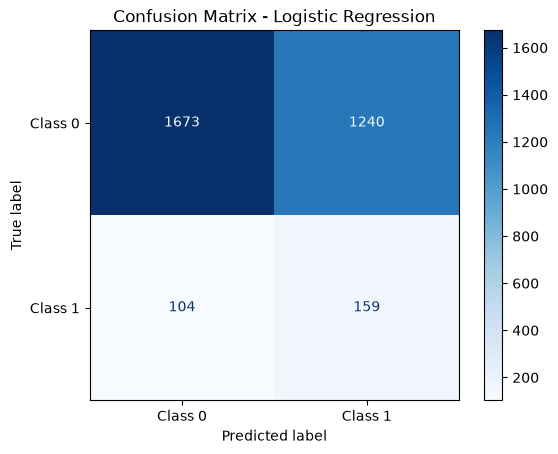

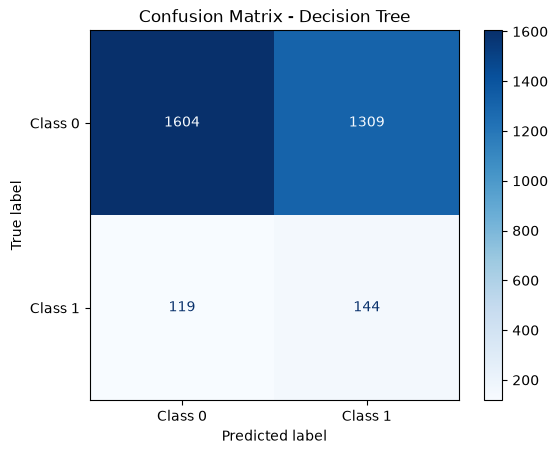

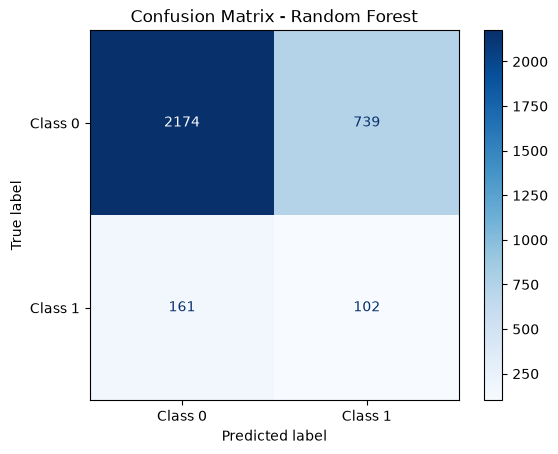

In [21]:
# Display a confusion matrix for each model to compare correct and incorrect predictions.

from sklearn.metrics import ConfusionMatrixDisplay

for name, pipeline in trained_models.items():

    y_pred = pipeline.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Class 0", "Class 1"],
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.show()


In [22]:
print(df["severity_index"].value_counts())

severity_index
0    14563
1     1315
Name: count, dtype: int64


# Findings

### Model Evaluation and Comparison

The trained classification models were evaluated using accuracy, precision, recall, F1 Score and Precision-Recall Area Under the Curve (PR-AUC). Confusion matrices were also generated to examine the correct and incorrect predictions made by each model.

The Logistic Regression model achieved an accuracy of 57.68%, precision of 11.37%, recall of 60.46%, F1 Score of 0.191 and PR-AUC of 0.121. Its confusion matrix showed that the model correctly classified 1,673 Class 0 observations and 159 Class 1 observations. However, it incorrectly classified 1,240 Class 0 observations as Class 1 and 104 Class 1 observations as Class 0.

Random Forest achieved the highest accuracy of 71.66% and precision of 12.13%. However, its recall was 38.78%, indicating that it identified a smaller proportion of actual Class 1 observations compared to Logistic Regression. Its F1 Score was 0.185, while its PR-AUC was 0.109.

The Decision Tree model recorded an accuracy of 55.04%, precision of 9.91%, recall of 54.75%, F1 Score of 0.168 and PR-AUC of 0.095. It recorded the lowest performance among the three models based on most of the evaluation metrics.

Overall, Logistic Regression achieved the highest recall, F1 Score and PR-AUC, making it the strongest candidate when identifying Class 1 observations is a priority. Random Forest achieved the highest accuracy, but its lower recall indicates that it missed a larger proportion of actual Class 1 observations. The relatively low precision values across all three models indicate that further improvements are needed to reduce incorrect Class 1 predictions.

## Conclusion

This project aimed to develop a machine learning model for predicting road crash severity using historical crash-related data.

The project involved data understanding, data cleaning, exploratory data analysis, feature engineering, model preparation, training and evaluation.

Three classification algorithms were tested: Logistic Regression, Decision Tree and Random Forest. Logistic Regression performed best in terms of Class 1 recall and F1-score, making it the preferred model among the three.

However, the results show that the model still has limitations, particularly its low precision and high number of false positive predictions.

The project demonstrates the potential of machine learning in analysing road crash data and supporting efforts to understand crash patterns. Further improvements are necessary before the model can be considered reliable for practical use.

## Recommendations

Based on the findings and limitations of this project, the following recommendations are proposed:

1. **Improve data quality:** Collect more complete and accurate crash records, particularly for records with missing temporal information.

2. **Use more relevant features:** Include additional factors such as road conditions, weather conditions, vehicle types, traffic volume and driver-related information where available.

3. **Address class imbalance:** Explore techniques such as SMOTE and other class-balancing methods to improve the model's ability to identify minority-class cases.

4. **Improve model performance:** Experiment with additional algorithms and hyperparameter tuning to improve prediction accuracy, precision and recall.

5. **Use reliable crash records:** Verify that the target severity labels represent actual crash outcomes and are not derived from the same information used as input features.

6. **Further testing:** Evaluate the model using additional and more recent crash data before considering real-world implementation.